# AR(3): track φ whenever the sphere descent finds a new best width

This notebook implements the supplied pseudocode: **keep the sphere descent unchanged**, and update the coefficient estimate $\widehat\phi$ whenever a new best width is accepted. The coefficients are recorded during the loop and never fed back into the next direction update.

Two corrections to the supplied pseudocode are used: update $\widehat w$ together with $\widehat u$ and $\widehat\phi$, and use $\gamma_t$ in both occurrences of the tangent step. Return the tracked coefficients together with the best direction. These are direct corrections based on the supplied algorithm, not a new estimation method.

Implementation: [projected_subgradient_empirical_width](ar_tools/descent.py), option `record_best_coefficients=True`. This follows the user's intended algorithm. The earlier [coefficient-space experiment](ar3_coefficient_space_descent.ipynb) also explored different update geometries, which are separate from this tracking proposal.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

AR_DIR=next(candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root/'Code'/'Code_AR_processes', root)
    if (candidate/'ar_tools/functions.py').is_file())
PROJECT_ROOT=AR_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.functions import simulate_uniform_ar, sliding_window_point_cloud

EXPERIMENT='ar3_best_coefficient_tracking'
DATA_DIR=AR_DIR/'outputs/csv'/EXPERIMENT
PDF_DIR=AR_DIR/'outputs/pdfs'/EXPERIMENT
IMAGE_DIR=AR_DIR/'outputs/images'/EXPERIMENT
for directory in (DATA_DIR,PDF_DIR,IMAGE_DIR):
    directory.mkdir(parents=True,exist_ok=True)
np.set_printoptions(precision=8,suppress=True)

Matplotlib created a temporary cache directory at /var/folders/tr/kt47kz8d61ngpcfl5d_s9fc80000gn/T/matplotlib-4_w9anb6 because the default path (/Users/iljasukhanov/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


## Update being tested

For newest-first AR(3) windows $x_i=(X_i,X_{i-1},X_{i-2},X_{i-3})$, use the empirical width and tangent update from [descent.py](ar_tools/descent.py):
$$w_P(u)=\max_i\langle x_i,u\rangle-\min_i\langle x_i,u\rangle,\quad
g_t=x_{i_t}-x_{j_t},\quad \xi_t=(I-u_tu_t^\top)g_t,$$
$$v_t=u_t-\gamma_t\xi_t,\qquad u_{t+1}=\frac{v_t}{\|v_t\|},\qquad \gamma_t=\gamma_0\beta^t.$$
Whenever $w_P(u_{t+1})<\widehat w$, perform **all three** assignments:
$$\widehat w\gets w_P(u_{t+1}),\qquad
\widehat u\gets u_{t+1},\qquad
\widehat\phi\gets-\frac{\widehat u_{1:3}}{\widehat u_0}.$$
Here $\widehat u_0$ denotes the first coordinate of the best direction, using zero-based coordinate indices. The initial direction is the time-indexed vector $u_{t=0}$.

These equations are a restatement of the supplied algorithm with its two corrections. Because $\widehat\phi$ occurs only in the recording assignments, tracking it cannot change the computed directions; this is an inference from the displayed algorithm. The checks below test exact equality of all recorded states with tracking switched off.

Use `improvement_tolerance=0.0` to implement the strict comparison. At a zero first coordinate the coefficient estimate is undefined; record NaN and continue the sphere search. Near-zero coordinates are not clipped. Index 0 in the saved data is the initial state, and index 1 is the first updated direction, following the existing optimizer's evaluation convention.

In [2]:
TRUE_PHI=np.array([0.5,-0.2,0.1])
T=1000
BURNIN=1000
PROCESS_SEED=20261018
OPTIMIZER_SEED=20261019
GAMMA0=0.1
BETA=0.997
EVALUATIONS=5000

series=simulate_uniform_ar(TRUE_PHI,T,burnin=BURNIN,rng=PROCESS_SEED)
points=sliding_window_point_cloud(series,4)
random_u=np.random.default_rng(OPTIMIZER_SEED).normal(size=4)
random_u/=np.linalg.norm(random_u)
starts={'Zero coefficients':np.array([1.,0.,0.,0.]),'Earlier random direction':random_u}
configuration=dict(true_phi=TRUE_PHI.tolist(),T=T,burnin=BURNIN,
    process_seed=PROCESS_SEED,optimizer_seed=OPTIMIZER_SEED,
    gamma0=GAMMA0,beta=BETA,evaluated_states=EVALUATIONS,
    patience='disabled',improvement_tolerance=0.,
    initial_directions={label:u.tolist() for label,u in starts.items()},
    coefficient_update='only on a strict best-width improvement; initial state included',
    objective='original unit-direction empirical width',
    coefficient_feedback=False)
(DATA_DIR/'configuration.json').write_text(json.dumps(configuration,indent=2)+'\n')
pd.DataFrame({'time':np.arange(1,T+1),'X_t':series}).to_csv(DATA_DIR/'process.csv',index=False)
print(f'AR(3) true coefficients: {TRUE_PHI}; T={T}')
print(f'Geometric steps: gamma0={GAMMA0}; beta={BETA}; evaluated states={EVALUATIONS}')

AR(3) true coefficients: [ 0.5 -0.2  0.1]; T=1000
Geometric steps: gamma0=0.1; beta=0.997; evaluated states=5000


## Run the original descent with and without coefficient tracking

Each pair uses the same path, initial direction, step sequence, evaluation budget and strict width comparison. The true coefficients are used only for the displayed coefficient errors. The code verifies that all directions, current widths, best widths and steps are exactly identical with tracking enabled and disabled. It also independently reconstructs the best-direction coefficients after the run and checks them against the estimates recorded inside the loop.

In [3]:
fits={}
rows=[]
frames=[]
with threadpool_limits(limits=1):
    for label,initial_direction in starts.items():
        settings=dict(points=points,initial_direction=initial_direction.copy(),
            iterations=EVALUATIONS,initial_step=GAMMA0,
            step_schedule='geometric',geometric_decay=BETA,
            patience=EVALUATIONS+1,improvement_tolerance=0.,record_directions=True)
        baseline=projected_subgradient_empirical_width(**settings)
        tracked=projected_subgradient_empirical_width(**settings,record_best_coefficients=True)
        for key in ['direction','direction_history','width_history','best_width_history','step_history']:
            np.testing.assert_array_equal(baseline[key],tracked[key])
        assert baseline['minimum_width']==tracked['minimum_width']
        updates=np.r_[True,np.diff(baseline['best_width_history'])<0]
        np.testing.assert_array_equal(tracked['best_update_history'],updates)
        best_indices=np.maximum.accumulate(np.where(updates,np.arange(EVALUATIONS),0))
        best_directions=baseline['direction_history'][best_indices]
        expected=-best_directions[:,1:]/best_directions[:,:1]
        np.testing.assert_array_equal(expected,tracked['best_coefficient_history'])
        final_phi=-baseline['direction'][1:]/baseline['direction'][0]
        np.testing.assert_array_equal(final_phi,tracked['coefficients'])
        fits[label]=tracked
        frame=pd.DataFrame({
            'start':label,'iteration':np.arange(EVALUATIONS),
            'current_width':tracked['width_history'],'best_width':tracked['best_width_history'],
            'step':tracked['step_history'],'best_updated':tracked['best_update_history'],
            'best_phi_1':tracked['best_coefficient_history'][:,0],
            'best_phi_2':tracked['best_coefficient_history'][:,1],
            'best_phi_3':tracked['best_coefficient_history'][:,2],
            'best_coefficient_l2_error':np.linalg.norm(tracked['best_coefficient_history']-TRUE_PHI,axis=1),
        })
        frames.append(frame)
        rows.append(dict(start=label,minimum_width=tracked['minimum_width'],
            phi_1=tracked['coefficients'][0],phi_2=tracked['coefficients'][1],phi_3=tracked['coefficients'][2],
            coefficient_l2_error=float(np.linalg.norm(tracked['coefficients']-TRUE_PHI)),
            best_updates_after_initialization=int(updates.sum()-1),
            same_directions=True,same_widths=True,same_final_coefficients=True))
history=pd.concat(frames,ignore_index=True)
summary=pd.DataFrame(rows)
history.to_csv(DATA_DIR/'iteration_history.csv',index=False)
history[history.best_updated].to_csv(DATA_DIR/'coefficient_updates.csv',index=False)
summary.to_csv(DATA_DIR/'summary.csv',index=False)
display(summary)
print('Verified: tracking leaves every recorded direction and width exactly unchanged.')
print('Verified: the final tracked coefficients equal one final inverse projection exactly.')

Verified: tracking leaves every recorded direction and width exactly unchanged.
Verified: the final tracked coefficients equal one final inverse projection exactly.


,start,minimum_width,phi_1,phi_2,phi_3,coefficient_l2_error,best_updates_after_initialization,same_directions,same_widths,same_final_coefficients
0,Zero coefficients,1.747612,0.500668,-0.203073,0.102515,0.004027,68,True,True,True
1,Earlier random direction,1.862952,27.493001,-14.014123,4.045696,30.578107,73,True,True,True


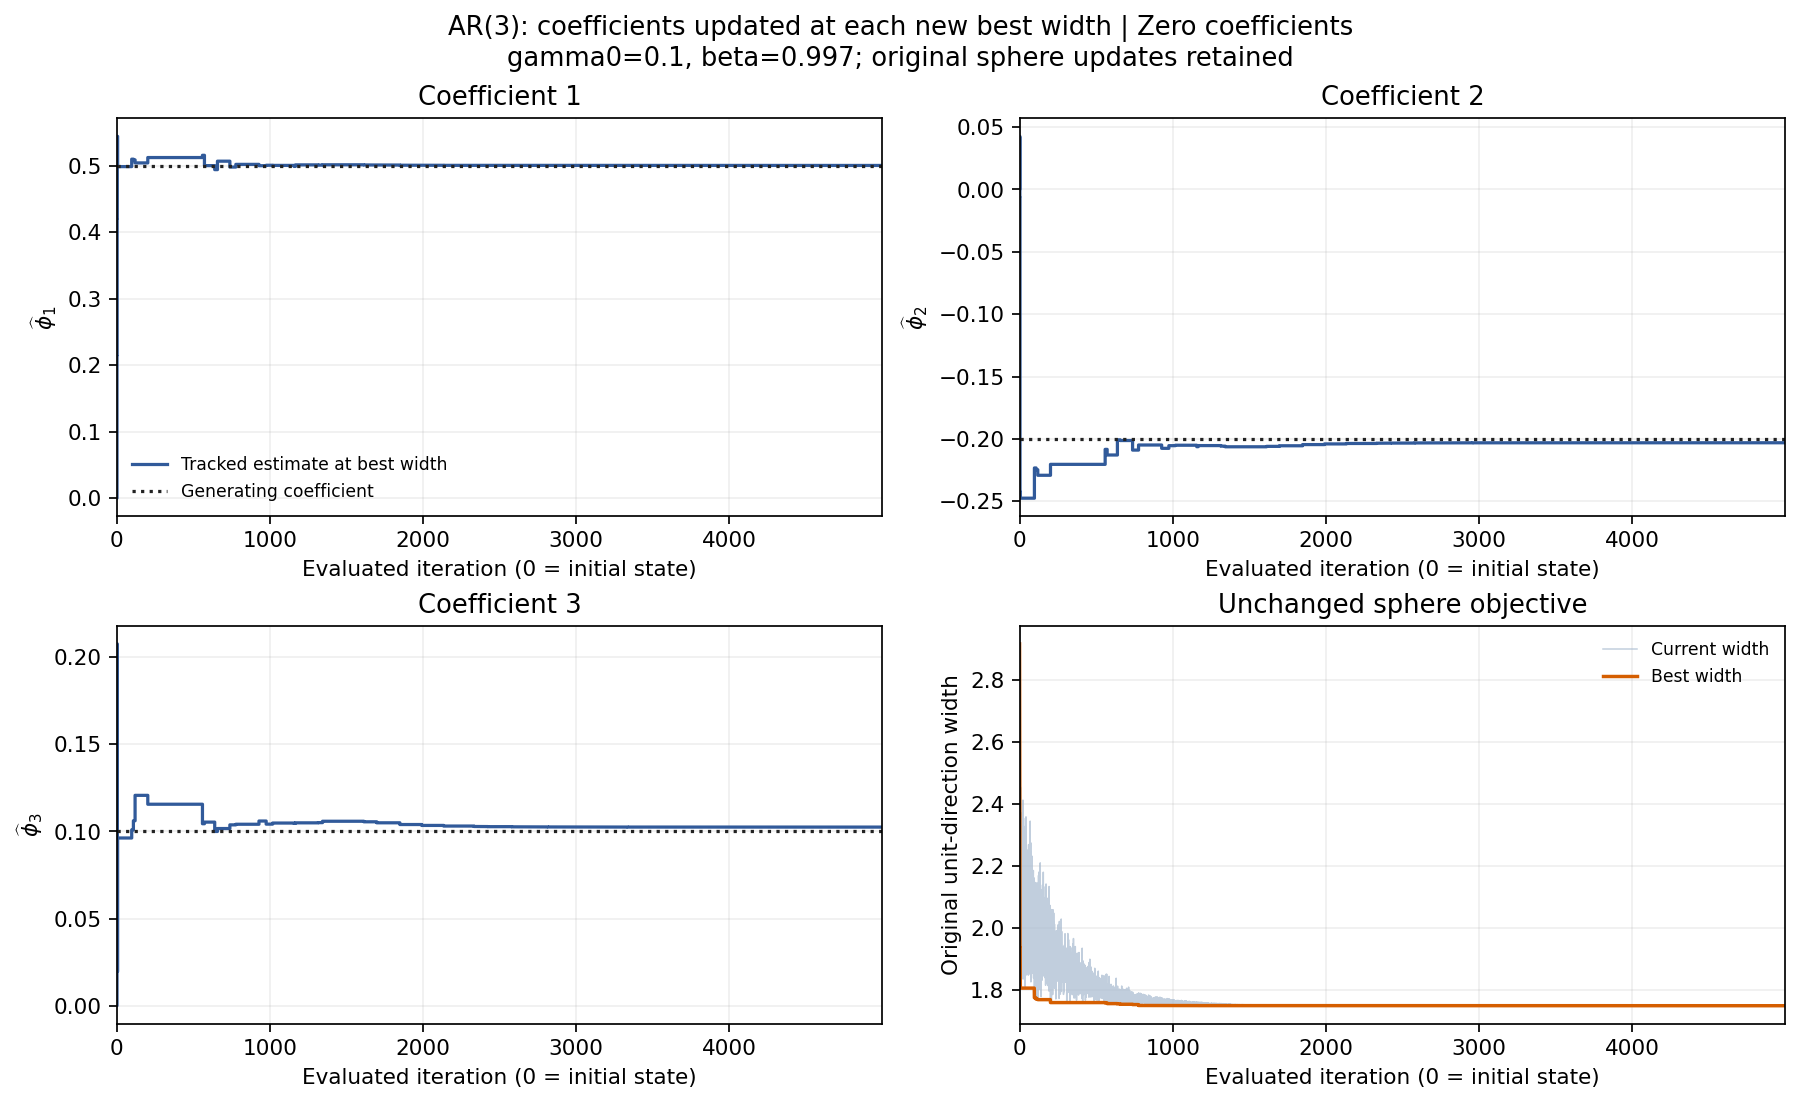

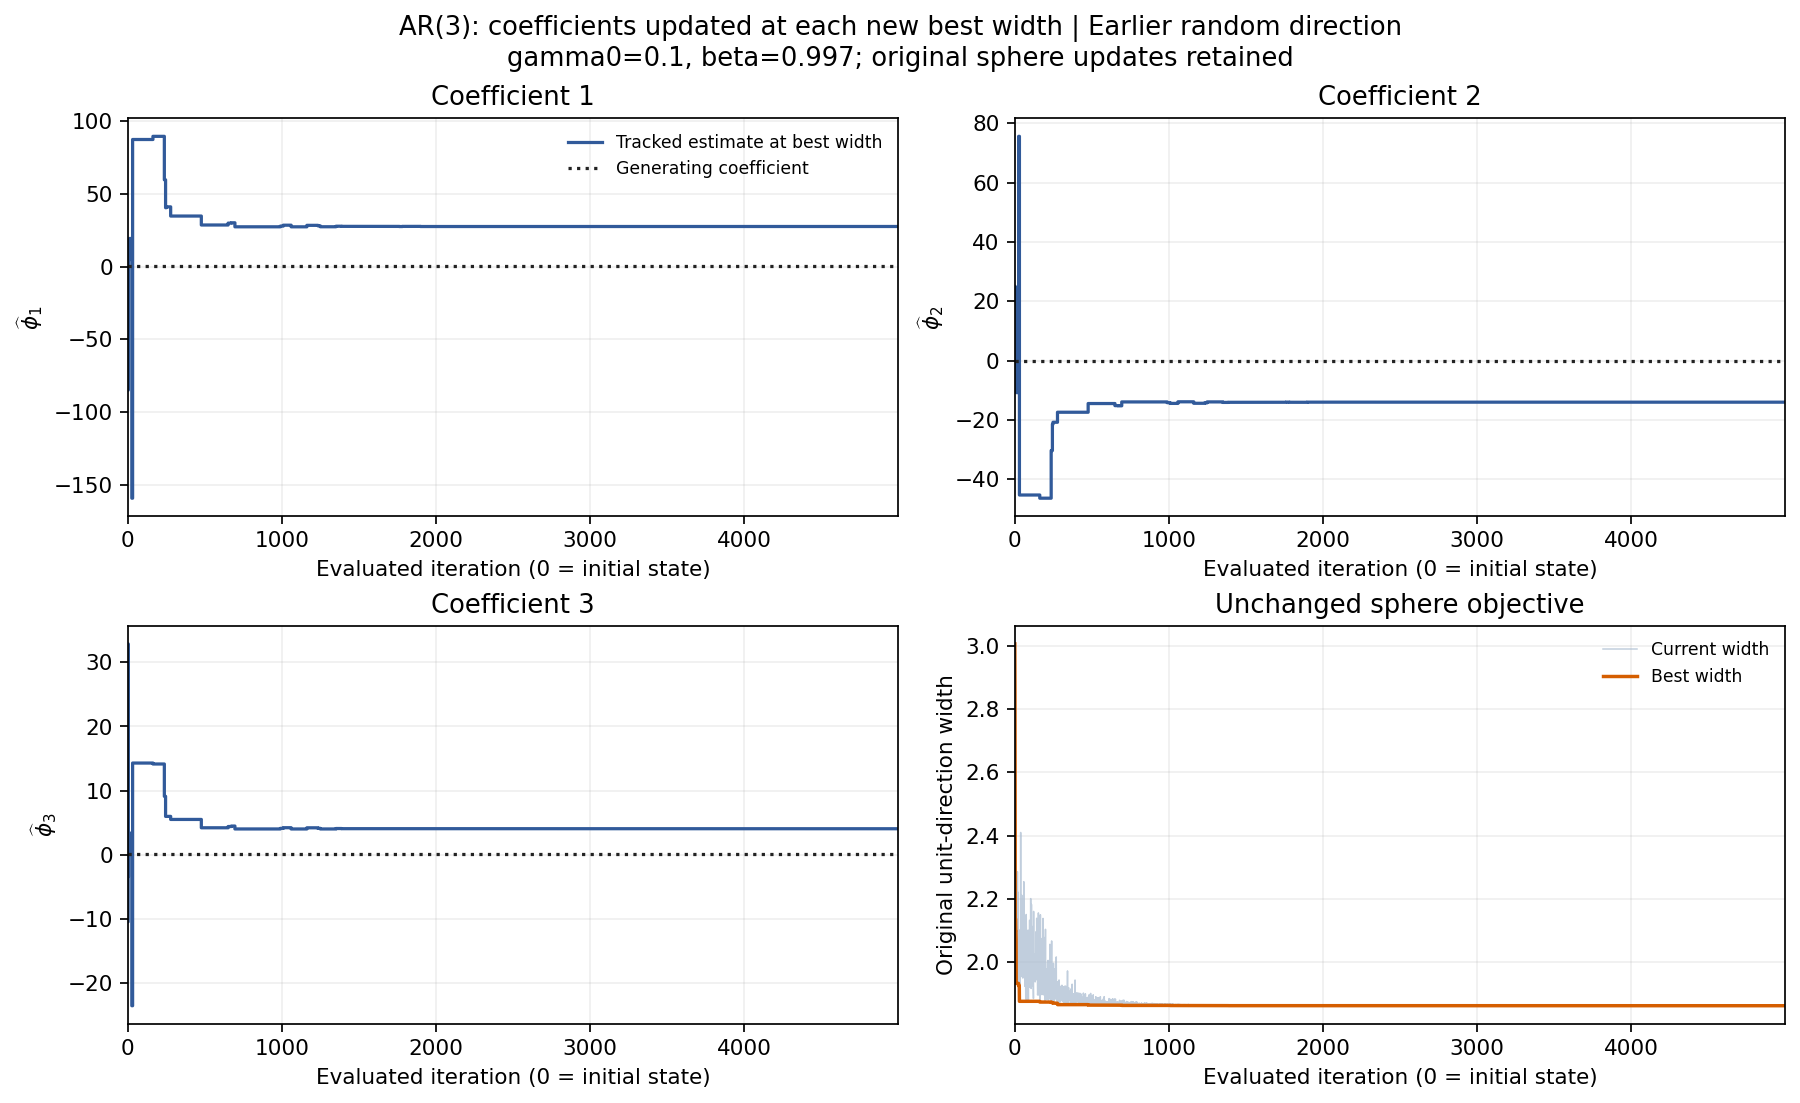

In [4]:
for label,stem in [('Zero coefficients','zero_start_tracking'),('Earlier random direction','random_start_tracking')]:
    frame=history[history.start==label]
    with plt.rc_context({'font.size':10,'pdf.fonttype':42}):
        fig,axes=plt.subplots(2,2,figsize=(11.5,7),constrained_layout=True)
        for j,ax in enumerate(axes.flat[:3]):
            ax.step(frame.iteration,frame[f'best_phi_{j+1}'],where='post',
                color='#315a9a',lw=1.5,label='Tracked estimate at best width')
            ax.axhline(TRUE_PHI[j],color='#222222',ls=':',label='Generating coefficient')
            ax.set(ylabel=rf'$\widehat\phi_{j+1}$',title=f'Coefficient {j+1}')
        axes.flat[0].legend(frameon=False,fontsize=8)
        axes[1,1].plot(frame.iteration,frame.current_width,color='#a7bacf',alpha=.7,lw=.7,label='Current width')
        axes[1,1].plot(frame.iteration,frame.best_width,color='#d55e00',lw=1.6,label='Best width')
        axes[1,1].set(ylabel='Original unit-direction width',title='Unchanged sphere objective')
        axes[1,1].legend(frameon=False,fontsize=8)
        for ax in axes.flat:
            ax.set(xlabel='Evaluated iteration (0 = initial state)',xlim=(0,EVALUATIONS-1))
            ax.grid(alpha=.2)
        fig.suptitle(f'AR(3): coefficients updated at each new best width | {label}\n'
                     f'gamma0={GAMMA0}, beta={BETA}; original sphere updates retained')
        fig.savefig(PDF_DIR/f'{stem}.pdf',bbox_inches='tight')
        fig.savefig(IMAGE_DIR/f'{stem}.png',dpi=155,bbox_inches='tight')
        plt.close(fig)
    display(Image(filename=str(IMAGE_DIR/f'{stem}.png')))

## Interpretation

This implementation provides the coefficient estimate throughout the run. It yields the same final estimate as applying inverse radial projection once to the returned best direction: both use the same $\widehat u$. This is an algebraic consequence of the supplied update, confirmed above by exact equality checks; it does not require a statistical performance claim.

A smaller width need not make the coefficient error relative to the generating vector smaller at every recorded improvement. The width is the optimization objective, while the true coefficient error is only a diagnostic. The saved histories let these quantities be examined separately for this sample.

The earlier coefficient-space experiment tested additional update rules; its conclusions about Euclidean coefficient descent are not conclusions about the tracking-only algorithm here. Source: [the implemented best-width update](ar_tools/descent.py).

In [5]:
lines=[
    '# Best-coefficient tracking during the unchanged AR(3) sphere descent',
    'This implements the user-supplied algorithm with two corrections: update the best width along with the best direction and coefficients, and use gamma_t consistently in the tangent step.',
    f'Example: true phi={TRUE_PHI.tolist()}, T={T}, process seed={PROCESS_SEED}, burn-in={BURNIN}; innovations Uniform[-1,1].',
    f'Schedule: gamma0={GAMMA0}, beta={BETA}; {EVALUATIONS} evaluated states; no patience stopping; strict best-width comparison.',
    '**Finding:** recording coefficients at each new best width leaves all recorded directions and widths exactly unchanged. The final tracked coefficients equal a single inverse projection of the returned best direction exactly for both starts.',
    '| Starting point | Best width | phi_1 | phi_2 | phi_3 | Updates after initialization |',
    '|---|---:|---:|---:|---:|---:|',
]
for row in summary.itertuples():
    lines.append(f'| {row.start} | {row.minimum_width:.10f} | {row.phi_1:.8f} | {row.phi_2:.8f} | {row.phi_3:.8f} | {row.best_updates_after_initialization} |')
lines.extend([
    '\nThe equality is an inference from the update itself and is also checked numerically: phi is never used to update a direction or choose a step. It is computed only when the best direction changes.',
    'A zero first direction coordinate makes the coefficient estimate undefined; the implementation records NaN and continues the sphere search. It does not clip small first coordinates.',
    'Sources: [implementation](../../../ar_tools/descent.py), projected_subgradient_empirical_width, record_best_coefficients; '
    '[notebook](../../../ar3_best_coefficient_tracking.ipynb), sections "Update being tested" and "Run the original descent with and without coefficient tracking"; '
    '[saved summary](summary.csv); [coefficient updates](coefficient_updates.csv); [all iterations](iteration_history.csv).',
])
report='\n\n'.join(lines[:5])+'\n\n'+'\n'.join(lines[5:])+'\n'
(DATA_DIR/'findings.md').write_text(report)
(DATA_DIR/'summary.json').write_text(json.dumps(dict(configuration,results=summary.to_dict(orient='records')),indent=2)+'\n')
display(Markdown(report))
print(f'PDF figures: {PDF_DIR}')

PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_best_coefficient_tracking


# Best-coefficient tracking during the unchanged AR(3) sphere descent

This implements the user-supplied algorithm with two corrections: update the best width along with the best direction and coefficients, and use gamma_t consistently in the tangent step.

Example: true phi=[0.5, -0.2, 0.1], T=1000, process seed=20261018, burn-in=1000; innovations Uniform[-1,1].

Schedule: gamma0=0.1, beta=0.997; 5000 evaluated states; no patience stopping; strict best-width comparison.

**Finding:** recording coefficients at each new best width leaves all recorded directions and widths exactly unchanged. The final tracked coefficients equal a single inverse projection of the returned best direction exactly for both starts.

| Starting point | Best width | phi_1 | phi_2 | phi_3 | Updates after initialization |
|---|---:|---:|---:|---:|---:|
| Zero coefficients | 1.7476115640 | 0.50066821 | -0.20307305 | 0.10251509 | 68 |
| Earlier random direction | 1.8629524395 | 27.49300123 | -14.01412340 | 4.04569640 | 73 |

The equality is an inference from the update itself and is also checked numerically: phi is never used to update a direction or choose a step. It is computed only when the best direction changes.
A zero first direction coordinate makes the coefficient estimate undefined; the implementation records NaN and continues the sphere search. It does not clip small first coordinates.
Sources: [implementation](../../../ar_tools/descent.py), projected_subgradient_empirical_width, record_best_coefficients; [notebook](../../../ar3_best_coefficient_tracking.ipynb), sections "Update being tested" and "Run the original descent with and without coefficient tracking"; [saved summary](summary.csv); [coefficient updates](coefficient_updates.csv); [all iterations](iteration_history.csv).
